In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import os
FIGDIR = "results/eda_visualizations"
os.makedirs(FIGDIR, exist_ok=True)

GLU = pd.read_csv("results/outputs/diabetes_glucose.csv")
print("loaded:", GLU.shape)
GLU.head()

loaded: (13511, 31)


,patient_id,timestamp,date,time,hour,time_of_day,day_of_week,is_weekend,reading_index,code,context,code_description,glucose_mg_dl,prev_glucose,prev_glucose_2,glucose_change,hours_since_prev,hours_to_next,rolling_mean_3,rolling_std_3,insulin_regular_6h,insulin_nph_6h,insulin_ultralente_6h,total_insulin_6h,daily_total_insulin,meals_6h,exercise_6h,hypo_symptoms_6h,risk_class,next_glucose,next_risk_class
0,1,1991-04-21 09:09:00,1991-04-21,09:09,9,morning,Sunday,True,1,58,pre_breakfast,Pre-breakfast blood glucose,100.0,NaN,NaN,NaN,NaN,7.983333,100.000000,NaN,9.0,13.0,0.0,22.0,29.0,0,0,0,Normal,119.0,Normal
1,1,1991-04-21 17:08:00,1991-04-21,17:08,17,afternoon,Sunday,True,2,62,pre_supper,Pre-supper blood glucose,119.0,100.0,NaN,19.0,7.983333,5.716667,109.500000,13.435029,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,123.0,Normal
2,1,1991-04-21 22:51:00,1991-04-21,22:51,22,night_late,Sunday,True,3,48,unspecified,Unspecified blood glucose measurement,123.0,119.0,100.0,4.0,5.716667,8.733333,114.000000,12.288206,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,216.0,Hyperglycemic
3,1,1991-04-22 07:35:00,1991-04-22,07:35,7,morning,Monday,False,4,58,pre_breakfast,Pre-breakfast blood glucose,216.0,123.0,119.0,93.0,8.733333,9.350000,152.666667,54.884728,10.0,13.0,0.0,23.0,32.0,0,0,0,Hyperglycemic,211.0,Hyperglycemic
4,1,1991-04-22 16:56:00,1991-04-22,16:56,16,afternoon,Monday,False,5,62,pre_supper,Pre-supper blood glucose,211.0,216.0,123.0,-5.0,9.350000,14.483333,183.333333,52.309974,9.0,0.0,0.0,9.0,32.0,0,0,0,Hyperglycemic,257.0,Hyperglycemic


In [2]:
GLU_clean = GLU.dropna(subset=["prev_glucose", "next_glucose"])\
               .drop(columns=["prev_glucose_2"]).copy()
print("working rows:", len(GLU_clean))

working rows: 13371


In [3]:
for c in ["context", "time_of_day", "day_of_week", "is_weekend"]:
    print(f"\n--- {c} ({GLU_clean[c].nunique()} levels) ---")
    print(GLU_clean[c].value_counts())


--- context (8 levels) ---
context
pre_breakfast     3468
pre_supper        3134
unspecified       2828
pre_lunch         2753
pre_snack          895
post_supper        212
post_lunch          66
post_breakfast      15
Name: count, dtype: int64

--- time_of_day (5 levels) ---
time_of_day
morning       4115
afternoon     3482
evening       3017
night_late    2245
night          512
Name: count, dtype: int64

--- day_of_week (7 levels) ---
day_of_week
Monday       2007
Wednesday    1986
Thursday     1930
Tuesday      1929
Friday       1883
Sunday       1833
Saturday     1803
Name: count, dtype: int64

--- is_weekend (2 levels) ---
is_weekend
False    9735
True     3636
Name: count, dtype: int64


### Encoding methods used, and why

There are four categorical fields, and each needs a different encoding because
each carries different structure — using one-hot for all of them would either
blow up the feature space or throw away real information:

| Column | Type | Method | Why |
|---|---|---|---|
| `is_weekend` | binary boolean | cast to `int` (0/1) | already 2 levels — no encoding scheme needed, just a numeric dtype |
| `context` | nominal, 8 levels (3 rare) | group rare levels → **one-hot** (`pd.get_dummies`) | no natural order between "pre_lunch" and "pre_supper" etc., so one-hot avoids implying a ranking. The 3 post-meal levels (`post_breakfast`=15, `post_lunch`=66, `post_supper`=212 rows) are merged into a single `post_meal` category first, since a one-hot column built from <300 rows (~2% of the data) would be too sparse for a model to learn from reliably |
| `time_of_day` | ordinal, 5 levels | **ordinal / label encoding** (explicit map night=0 → night_late=4) | there is a genuine real-world order (night < morning < afternoon < evening < night_late), so one-hot would throw away that ordering information a single ordinal column preserves |
| `day_of_week` | cyclical, 7 levels | **cyclical encoding** (`sin`/`cos` of the day-of-week angle) | the days wrap around (Sunday is adjacent to Monday), which neither one-hot nor a plain 0–6 ordinal can represent — sin/cos places the 7 days on a circle so adjacent days stay numerically close |



In [4]:
GLU_enc = GLU_clean.copy()

# 1. is_weekend — already binary
GLU_enc["is_weekend"] = GLU_enc["is_weekend"].astype(int)

# 2. context — group the three rare post-meal levels, then one-hot
GLU_enc["context_grouped"] = GLU_enc["context"].replace({
    "post_breakfast": "post_meal",
    "post_lunch":     "post_meal",
    "post_supper":    "post_meal",
})
ctx = pd.get_dummies(GLU_enc["context_grouped"], prefix="ctx", dtype=int)

# 3. time_of_day — genuine ordering, so ordinal
tod_order = {"night": 0, "morning": 1, "afternoon": 2, "evening": 3, "night_late": 4}
GLU_enc["time_of_day_ord"] = GLU_enc["time_of_day"].map(tod_order)

# 4. day_of_week — cyclical
dow_order = {"Monday":0,"Tuesday":1,"Wednesday":2,"Thursday":3,
             "Friday":4,"Saturday":5,"Sunday":6}
dow_num = GLU_enc["day_of_week"].map(dow_order)
GLU_enc["dow_sin"] = np.sin(2 * np.pi * dow_num / 7)
GLU_enc["dow_cos"] = np.cos(2 * np.pi * dow_num / 7)

GLU_enc = pd.concat([GLU_enc, ctx], axis=1)
GLU_enc = GLU_enc.drop(columns=["context", "context_grouped",
                                "time_of_day", "day_of_week"])

print("before:", GLU_clean.shape)
print("after: ", GLU_enc.shape)
print("\nnew columns:", [c for c in GLU_enc.columns if c not in GLU_clean.columns])

before: (13371, 30)
after:  (13371, 36)

new columns: ['time_of_day_ord', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']


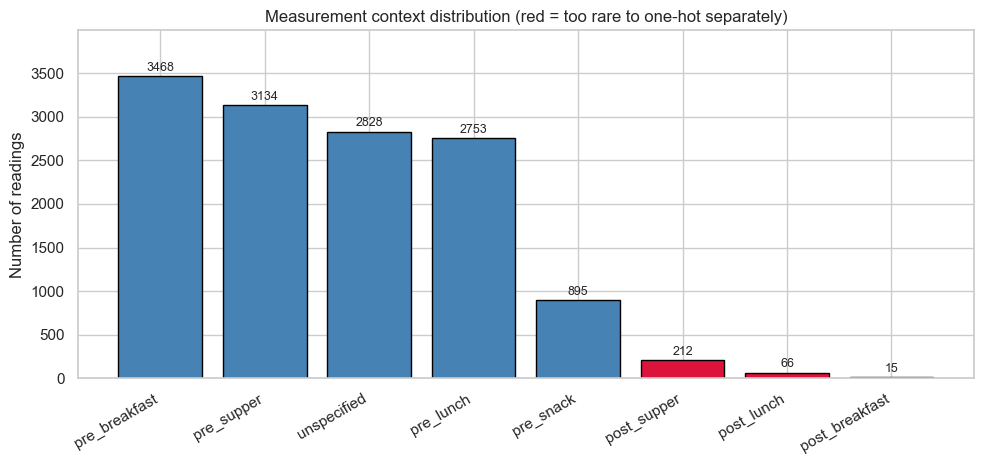

In [5]:
counts = GLU_clean.context.value_counts()
colors = ["crimson" if v < 300 else "steelblue" for v in counts.values]

plt.figure(figsize=(10, 4.8))
bars = plt.bar(counts.index, counts.values, color=colors, edgecolor="black")
for b, v in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width()/2, v + 60, str(v), ha="center", fontsize=9)
plt.xticks(rotation=30, ha="right")
plt.ylabel("Number of readings")
plt.title("Measurement context distribution (red = too rare to one-hot separately)")
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/context_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

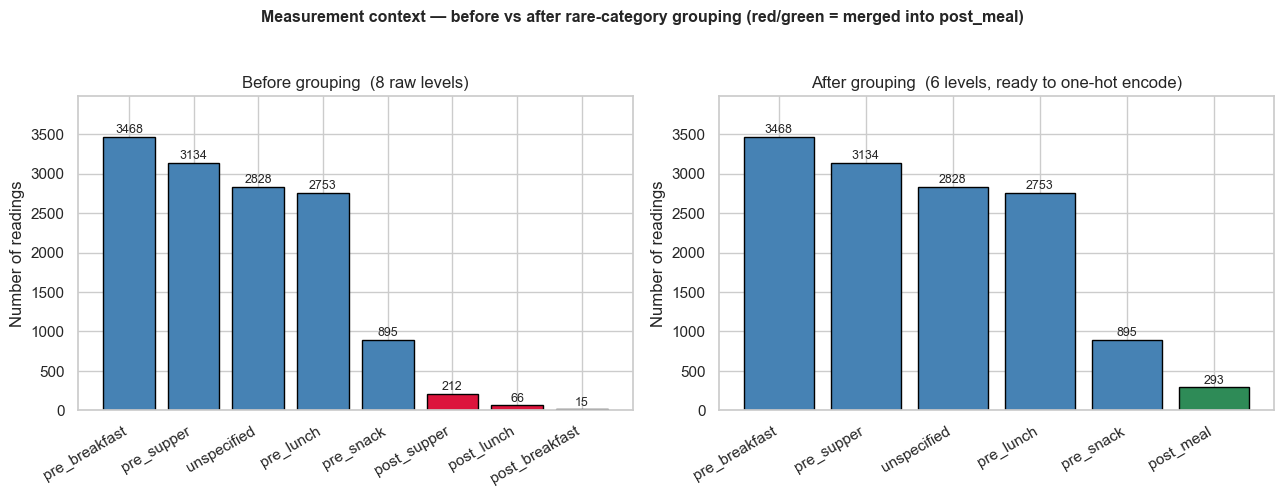

In [6]:
before_counts = GLU_clean["context"].value_counts()
grouped = GLU_clean["context"].replace({
    "post_breakfast": "post_meal", "post_lunch": "post_meal", "post_supper": "post_meal",
})
after_counts = grouped.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

colors0 = ["crimson" if v < 300 else "steelblue" for v in before_counts.values]
b0 = axes[0].bar(before_counts.index, before_counts.values, color=colors0, edgecolor="black")
for b, v in zip(b0, before_counts.values):
    axes[0].text(b.get_x()+b.get_width()/2, v + before_counts.max()*0.015, str(v), ha="center", fontsize=9)
axes[0].set_title(f"Before grouping  ({before_counts.shape[0]} raw levels)")
axes[0].set_ylabel("Number of readings")
axes[0].set_ylim(0, before_counts.max()*1.15)
axes[0].tick_params(axis="x", rotation=30)
for lbl in axes[0].get_xticklabels():
    lbl.set_ha("right")

colors1 = ["seagreen" if idx == "post_meal" else "steelblue" for idx in after_counts.index]
b1 = axes[1].bar(after_counts.index, after_counts.values, color=colors1, edgecolor="black")
for b, v in zip(b1, after_counts.values):
    axes[1].text(b.get_x()+b.get_width()/2, v + before_counts.max()*0.015, str(v), ha="center", fontsize=9)
axes[1].set_title(f"After grouping  ({after_counts.shape[0]} levels, ready to one-hot encode)")
axes[1].set_ylabel("Number of readings")
axes[1].set_ylim(0, before_counts.max()*1.15)
axes[1].tick_params(axis="x", rotation=30)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha("right")

fig.suptitle("Measurement context — before vs after rare-category grouping (red/green = merged into post_meal)",
             fontsize=11.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/context_encoding_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation

**Chart 1 (context distribution, before any changes)** shows why grouping was
needed in the first place: 3 of the 8 `context` levels (highlighted in red) have
fewer than 300 readings each, with `post_breakfast` at just 15.

**Chart 2 (before vs after grouping)** shows the fix: the three rare post-meal
levels collapse into one `post_meal` category (green, 293 readings — comparable
in size to the other levels), leaving 6 balanced categories that are one-hot
encoded in the next step. No information is discarded — only the granularity of
*when* a post-meal reading was taken is merged, since "which meal" carried too
little data per class to be useful to a model regardless.

In [7]:
GLU_enc.to_csv("results/outputs/02_encoded.csv", index=False)
print("saved:", GLU_enc.shape)

saved: (13371, 36)
